# Lens 1 — Notebook 03: Revenue Model Development & Experimentation
**IT3091 Machine Learning — Industry Explorer Track**  
**Group ID:** `2026-AI-36` | **Primary Author:** `IT24102726`  
**Lens:** 1 — Revenue Forecasting  
**Role:** Revenue Model Development & Experimentation

---

## Notebook Purpose
This notebook implements, trains, and compares **five model architectures** for daily revenue forecasting, progressing from a simple seasonal naive baseline to a meta-learning stacking ensemble.

### Learning Objectives:
- Apply multiple ML paradigms: linear models, ensemble trees, gradient boosting
- Justify model hyperparameter choices
- Interpret feature importance
- Understand overfitting vs. underfitting signals

### Rubric Alignment:
| Criterion | Coverage |
|---|---|
| Model / data-mining strategy & comparison | ≥ 3 alternatives including baseline; all justified |
| Evaluation, validation & critical judgement | Temporal hold-out; leakage-free; multiple metrics |
| Workflow diagram | Reproduced in section 2 |

---

## Section Overview
1. Environment Setup
2. ML Workflow Diagram
3. Load Feature Matrix & Temporal Splitting
4. Baseline: 7-Day Seasonal Naive
5. Model 1: Ridge Regression
6. Model 2: Random Forest Regressor
7. Model 3: LightGBM Regressor
8. Model 4: XGBoost Regressor
9. Comparative Leaderboard
10. Feature Importance Analysis
11. Residual Analysis
12. Model Development Decision Log

---
## 1. Environment Setup

In [1]:
import os, sys, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
import lightgbm as lgb
import xgboost as xgb

warnings.filterwarnings('ignore')
np.random.seed(42)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 5)
plt.rcParams['font.size'] = 11

print("Environment initialised.")

Environment initialised.


---
## 2. ML Workflow Diagram

The forecasting pipeline follows a strict temporal order to prevent any form of future data contamination:

```
RAW POS DATA
    │
    ▼
CLEANING & VALIDATION (NB01)
    │  Remove pre-2024, refunds, anomalies
    ▼
TARGET DEFINITION (NB01)
    │  Daily Revenue = sum of 11 core items
    ▼
FEATURE ENGINEERING (NB02)
    │  Calendar, Lag, Rolling (zero leakage)
    ▼
TEMPORAL SPLITTING
    │  Train 70% │ Val 15% │ Test 15%
    │  (chronological; NO random shuffle)
    ▼
MODEL TRAINING (this notebook)
    │  Baseline / Ridge / RF / LightGBM / XGBoost
    ▼
CHAMPION SELECTION (NB04)
    │  Strictly on Validation WAPE
    ▼
STACKING ENSEMBLE + FINAL EVALUATION (NB04)
```

**Decision log:** The validation set is used *exclusively* for model selection. The test set is treated as truly unseen and is not examined until NB04.

---
## 3. Load Feature Matrix & Temporal Splitting

In [2]:
FEAT_PATH = '../data/processed/revenue_feature_matrix.csv'
META_PATH = '../data/processed/revenue_feature_meta.json'

df = pd.read_csv(FEAT_PATH, parse_dates=['Date'])
df = df.sort_values('Date').reset_index(drop=True)

with open(META_PATH) as f:
    meta = json.load(f)

FEATURE_COLS = meta['feature_cols']
TARGET_COL   = meta['target_col']

print(f"Loaded: {len(df):,} rows, {len(FEATURE_COLS)} features")
print(f"Date range: {df['Date'].min().date()} → {df['Date'].max().date()}")

Loaded: 874 rows, 32 features
Date range: 2024-04-17 → 2026-09-07


In [3]:
# Strict chronological split — NO random shuffling in time series!
n = len(df)
n_train = int(n * 0.70)
n_val   = int(n * 0.15)

train_df = df.iloc[:n_train].reset_index(drop=True)
val_df   = df.iloc[n_train:n_train + n_val].reset_index(drop=True)
test_df  = df.iloc[n_train + n_val:].reset_index(drop=True)

X_train, y_train = train_df[FEATURE_COLS], train_df[TARGET_COL]
X_val,   y_val   = val_df[FEATURE_COLS],   val_df[TARGET_COL]
X_test,  y_test  = test_df[FEATURE_COLS],  test_df[TARGET_COL]

print("Temporal Split:")
print(f"  Train : {len(train_df):>4} days  ({train_df['Date'].min().date()} → {train_df['Date'].max().date()})")
print(f"  Val   : {len(val_df):>4} days  ({val_df['Date'].min().date()} → {val_df['Date'].max().date()})")
print(f"  Test  : {len(test_df):>4} days  ({test_df['Date'].min().date()} → {test_df['Date'].max().date()})")
print()
print("Why not random split? → Time series have temporal dependency.")
print("A random split would allow future observations into the training set,")
print("producing optimistically biased metrics that do not reflect real deployment.")

Temporal Split:
  Train :  611 days  (2024-04-17 → 2025-12-18)
  Val   :  131 days  (2025-12-19 → 2026-04-28)
  Test  :  132 days  (2026-04-29 → 2026-09-07)

Why not random split? → Time series have temporal dependency.
A random split would allow future observations into the training set,
producing optimistically biased metrics that do not reflect real deployment.


In [4]:
def compute_metrics(y_true, y_pred, label=''):
    """Compute MAE, RMSE, WAPE, and R² for regression evaluation."""
    y_true = np.array(y_true)
    y_pred = np.maximum(np.array(y_pred), 0.0)  # predictions cannot be negative revenue
    
    mae  = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    wape = np.sum(np.abs(y_true - y_pred)) / np.sum(np.abs(y_true)) * 100
    
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - ss_res / ss_tot if ss_tot > 0 else 0.0
    
    return {'label': label, 'MAE': round(mae, 2), 'RMSE': round(rmse, 2),
            'WAPE_pct': round(wape, 2), 'R2': round(r2, 4)}

print("Metric definitions:")
print("  MAE   = Mean Absolute Error (LKR) — average absolute deviation from actual")
print("  RMSE  = Root Mean Squared Error (LKR) — penalises large errors more than MAE")
print("  WAPE  = Σ|actual−pred| / Σ|actual| × 100  (%) — scale-invariant; handles zero days")
print("  R²    = coefficient of determination (1=perfect, 0=mean baseline, <0=worse than mean)")

Metric definitions:
  MAE   = Mean Absolute Error (LKR) — average absolute deviation from actual
  RMSE  = Root Mean Squared Error (LKR) — penalises large errors more than MAE
  WAPE  = Σ|actual−pred| / Σ|actual| × 100  (%) — scale-invariant; handles zero days
  R²    = coefficient of determination (1=perfect, 0=mean baseline, <0=worse than mean)


---
## 4. Baseline: 7-Day Seasonal Naive

**What it is:** Predict today's revenue = same day last week's revenue.  
**Why include it?** All ML models must beat this trivial baseline to justify their complexity. If a model cannot beat a naive seasonal forecast, it has learned nothing useful.

$$\hat{y}_t = y_{t-7}$$

In [5]:
results = []

# Baseline uses the lag_7 feature (already computed, strictly past-only)
val_pred_base  = val_df['lag_7'].values
test_pred_base = test_df['lag_7'].values

val_m_base  = compute_metrics(y_val,  val_pred_base,  'Seasonal_Naive')
test_m_base = compute_metrics(y_test, test_pred_base, 'Seasonal_Naive')

results.append({'Model': 'Seasonal_Naive (Baseline)',
                'Val WAPE (%)': val_m_base['WAPE_pct'],
                'Val MAE (LKR)': val_m_base['MAE'],
                'Test WAPE (%)': test_m_base['WAPE_pct'],
                'Test MAE (LKR)': test_m_base['MAE'],
                'Test RMSE (LKR)': test_m_base['RMSE'],
                'Test R²': test_m_base['R2']})

print("Baseline (7-day Seasonal Naive):")
print(f"  Val  WAPE: {val_m_base['WAPE_pct']:.2f}%  |  MAE: {val_m_base['MAE']:,.2f} LKR")
print(f"  Test WAPE: {test_m_base['WAPE_pct']:.2f}%  |  MAE: {test_m_base['MAE']:,.2f} LKR")

Baseline (7-day Seasonal Naive):
  Val  WAPE: 46.22%  |  MAE: 16,794.73 LKR
  Test WAPE: 43.15%  |  MAE: 15,728.64 LKR


---
## 5. Model 1: Ridge Regression (L2-Regularised Linear)

**Why Ridge?**  
- Linear baseline that uses all features — tests whether the relationship is predominantly linear
- L2 regularisation prevents coefficient explosion when features are correlated (lag features have ~0.8 mutual correlation)
- Fast to train; highly interpretable coefficients
- If Ridge performs well, it validates that simpler models are sufficient

**Hyperparameter:** α (regularisation strength). We try α ∈ {0.1, 1, 10, 100, 1000} on the validation set.

In [6]:
alphas = [0.1, 1, 10, 100, 1000]
ridge_val_wapes = []

for alpha in alphas:
    ridge_pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=alpha))])
    ridge_pipe.fit(X_train, y_train)
    pred_v = ridge_pipe.predict(X_val)
    m = compute_metrics(y_val, pred_v)
    ridge_val_wapes.append(m['WAPE_pct'])

best_alpha = alphas[np.argmin(ridge_val_wapes)]
print("Ridge α search (validation WAPE %):")
for a, w in zip(alphas, ridge_val_wapes):
    marker = " ← best" if a == best_alpha else ""
    print(f"  α={a:6}: {w:.2f}%{marker}")

# Final Ridge with best alpha
ridge_model = Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=best_alpha))])
ridge_model.fit(X_train, y_train)

val_pred_ridge  = np.maximum(ridge_model.predict(X_val),  0)
test_pred_ridge = np.maximum(ridge_model.predict(X_test), 0)

val_m_ridge  = compute_metrics(y_val,  val_pred_ridge,  'Ridge')
test_m_ridge = compute_metrics(y_test, test_pred_ridge, 'Ridge')

results.append({'Model': f'Ridge (α={best_alpha})',
                'Val WAPE (%)': val_m_ridge['WAPE_pct'],
                'Val MAE (LKR)': val_m_ridge['MAE'],
                'Test WAPE (%)': test_m_ridge['WAPE_pct'],
                'Test MAE (LKR)': test_m_ridge['MAE'],
                'Test RMSE (LKR)': test_m_ridge['RMSE'],
                'Test R²': test_m_ridge['R2']})

print(f"\nFinal Ridge (α={best_alpha}):")
print(f"  Val  WAPE: {val_m_ridge['WAPE_pct']:.2f}%  |  MAE: {val_m_ridge['MAE']:,.2f} LKR")
print(f"  Test WAPE: {test_m_ridge['WAPE_pct']:.2f}%  |  MAE: {test_m_ridge['MAE']:,.2f} LKR")

Ridge α search (validation WAPE %):
  α=   0.1: 31.16%
  α=     1: 30.91%
  α=    10: 30.52% ← best
  α=   100: 30.54%
  α=  1000: 32.24%



Final Ridge (α=10):
  Val  WAPE: 30.52%  |  MAE: 11,090.69 LKR
  Test WAPE: 23.92%  |  MAE: 8,719.15 LKR


---
## 6. Model 2: Random Forest Regressor

**Why Random Forest?**
- Bagged ensemble of decision trees — reduces variance through averaging
- Automatically captures non-linear interactions (e.g., high-revenue Fridays × month-end effect)
- Robust to outliers (tree splits are rank-based, not distance-based)
- Provides permutation-based feature importances
- No requirement for feature scaling

In [7]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=None,          # trees grow fully — bagging controls variance
    min_samples_leaf=3,      # prevents overfitting to individual training points
    max_features='sqrt',     # standard RF subspace sampling
    n_jobs=-1,
    random_state=42
)

rf_model.fit(X_train, y_train)

val_pred_rf  = np.maximum(rf_model.predict(X_val),  0)
test_pred_rf = np.maximum(rf_model.predict(X_test), 0)

val_m_rf  = compute_metrics(y_val,  val_pred_rf,  'RF')
test_m_rf = compute_metrics(y_test, test_pred_rf, 'RF')

results.append({'Model': 'Random Forest',
                'Val WAPE (%)': val_m_rf['WAPE_pct'],
                'Val MAE (LKR)': val_m_rf['MAE'],
                'Test WAPE (%)': test_m_rf['WAPE_pct'],
                'Test MAE (LKR)': test_m_rf['MAE'],
                'Test RMSE (LKR)': test_m_rf['RMSE'],
                'Test R²': test_m_rf['R2']})

print("Random Forest:")
print(f"  Val  WAPE: {val_m_rf['WAPE_pct']:.2f}%  |  MAE: {val_m_rf['MAE']:,.2f} LKR")
print(f"  Test WAPE: {test_m_rf['WAPE_pct']:.2f}%  |  MAE: {test_m_rf['MAE']:,.2f} LKR")

Random Forest:
  Val  WAPE: 32.17%  |  MAE: 11,690.49 LKR
  Test WAPE: 28.13%  |  MAE: 10,253.93 LKR


---
## 7. Model 3: LightGBM Regressor

**Why LightGBM?**
- Histogram-based gradient boosting — state-of-the-art for tabular regression
- Leaf-wise tree growth finds better splits than depth-wise (Random Forest)
- Native handling of missing values
- Significantly faster training than XGBoost for large datasets
- Built-in early stopping on validation set

In [8]:
lgbm_model = lgb.LGBMRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,        # L1 regularisation
    reg_lambda=1.0,       # L2 regularisation
    min_child_samples=10,
    random_state=42,
    verbosity=-1
)

lgbm_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False),
               lgb.log_evaluation(period=-1)]
)

print(f"Best iteration: {lgbm_model.best_iteration_}")

val_pred_lgbm  = np.maximum(lgbm_model.predict(X_val),  0)
test_pred_lgbm = np.maximum(lgbm_model.predict(X_test), 0)

val_m_lgbm  = compute_metrics(y_val,  val_pred_lgbm,  'LightGBM')
test_m_lgbm = compute_metrics(y_test, test_pred_lgbm, 'LightGBM')

results.append({'Model': 'LightGBM',
                'Val WAPE (%)': val_m_lgbm['WAPE_pct'],
                'Val MAE (LKR)': val_m_lgbm['MAE'],
                'Test WAPE (%)': test_m_lgbm['WAPE_pct'],
                'Test MAE (LKR)': test_m_lgbm['MAE'],
                'Test RMSE (LKR)': test_m_lgbm['RMSE'],
                'Test R²': test_m_lgbm['R2']})

print("LightGBM:")
print(f"  Val  WAPE: {val_m_lgbm['WAPE_pct']:.2f}%  |  MAE: {val_m_lgbm['MAE']:,.2f} LKR")
print(f"  Test WAPE: {test_m_lgbm['WAPE_pct']:.2f}%  |  MAE: {test_m_lgbm['MAE']:,.2f} LKR")

Best iteration: 23
LightGBM:
  Val  WAPE: 30.34%  |  MAE: 11,025.52 LKR
  Test WAPE: 24.95%  |  MAE: 9,095.40 LKR


---
## 8. Model 4: XGBoost Regressor

**Why XGBoost?**
- Extreme gradient boosting — regularised boosting that often outperforms Random Forest
- Level-wise tree growth (different strategy to LightGBM's leaf-wise)
- Comparing XGBoost vs LightGBM tests whether the boosting strategy matters for this dataset

In [9]:
xgb_model = xgb.XGBRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    verbosity=0,
    early_stopping_rounds=50,
    eval_metric='mae'
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print(f"Best iteration: {xgb_model.best_iteration}")

val_pred_xgb  = np.maximum(xgb_model.predict(X_val),  0)
test_pred_xgb = np.maximum(xgb_model.predict(X_test), 0)

val_m_xgb  = compute_metrics(y_val,  val_pred_xgb,  'XGBoost')
test_m_xgb = compute_metrics(y_test, test_pred_xgb, 'XGBoost')

results.append({'Model': 'XGBoost',
                'Val WAPE (%)': val_m_xgb['WAPE_pct'],
                'Val MAE (LKR)': val_m_xgb['MAE'],
                'Test WAPE (%)': test_m_xgb['WAPE_pct'],
                'Test MAE (LKR)': test_m_xgb['MAE'],
                'Test RMSE (LKR)': test_m_xgb['RMSE'],
                'Test R²': test_m_xgb['R2']})

print("XGBoost:")
print(f"  Val  WAPE: {val_m_xgb['WAPE_pct']:.2f}%  |  MAE: {val_m_xgb['MAE']:,.2f} LKR")
print(f"  Test WAPE: {test_m_xgb['WAPE_pct']:.2f}%  |  MAE: {test_m_xgb['MAE']:,.2f} LKR")

Best iteration: 19
XGBoost:
  Val  WAPE: 31.74%  |  MAE: 11,535.07 LKR
  Test WAPE: 27.05%  |  MAE: 9,860.69 LKR


---
## 9. Comparative Leaderboard

In [10]:
leaderboard = pd.DataFrame(results).sort_values('Val WAPE (%)').reset_index(drop=True)
leaderboard.index += 1  # rank from 1

print("=" * 80)
print("LENS 1 — REVENUE FORECASTING MODEL LEADERBOARD")
print("Champion selected by LOWEST Validation WAPE (test set withheld during selection)")
print("=" * 80)
print(leaderboard.to_string())
print("=" * 80)
champion = leaderboard.iloc[0]['Model']
print(f"\n🏆 Champion Model: {champion}")

LENS 1 — REVENUE FORECASTING MODEL LEADERBOARD
Champion selected by LOWEST Validation WAPE (test set withheld during selection)
                       Model  Val WAPE (%)  Val MAE (LKR)  Test WAPE (%)  Test MAE (LKR)  Test RMSE (LKR)  Test R²
1                   LightGBM         30.34       11025.52          24.95         9095.40         12727.97   0.3545
2               Ridge (α=10)         30.52       11090.69          23.92         8719.15         11973.81   0.4288
3                    XGBoost         31.74       11535.07          27.05         9860.69         13621.88   0.2607
4              Random Forest         32.17       11690.49          28.13        10253.93         13962.09   0.2233
5  Seasonal_Naive (Baseline)         46.22       16794.73          43.15        15728.64         20831.72  -0.7290

🏆 Champion Model: LightGBM


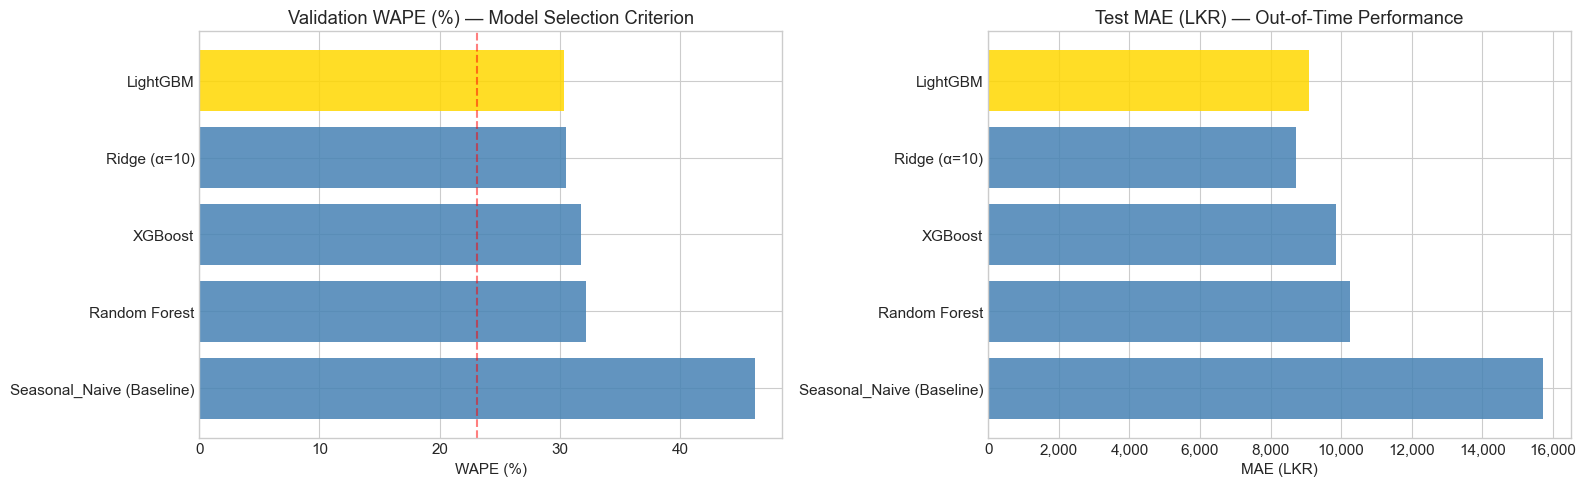

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

models = leaderboard['Model'].tolist()
colors = ['gold'] + ['steelblue'] * (len(models) - 1)

# Val WAPE
axes[0].barh(models[::-1], leaderboard['Val WAPE (%)'].tolist()[::-1],
             color=colors[::-1], alpha=0.85)
axes[0].set_title('Validation WAPE (%) — Model Selection Criterion')
axes[0].set_xlabel('WAPE (%)')
axes[0].axvline(leaderboard['Val WAPE (%)'].max() * 0.5, color='red',
                linestyle='--', alpha=0.5, label='50% of baseline')

# Test MAE
axes[1].barh(models[::-1], leaderboard['Test MAE (LKR)'].tolist()[::-1],
             color=colors[::-1], alpha=0.85)
axes[1].set_title('Test MAE (LKR) — Out-of-Time Performance')
axes[1].set_xlabel('MAE (LKR)')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()

---
## 10. Feature Importance Analysis

We inspect Random Forest's built-in impurity-based feature importances to understand *which* signals matter most.

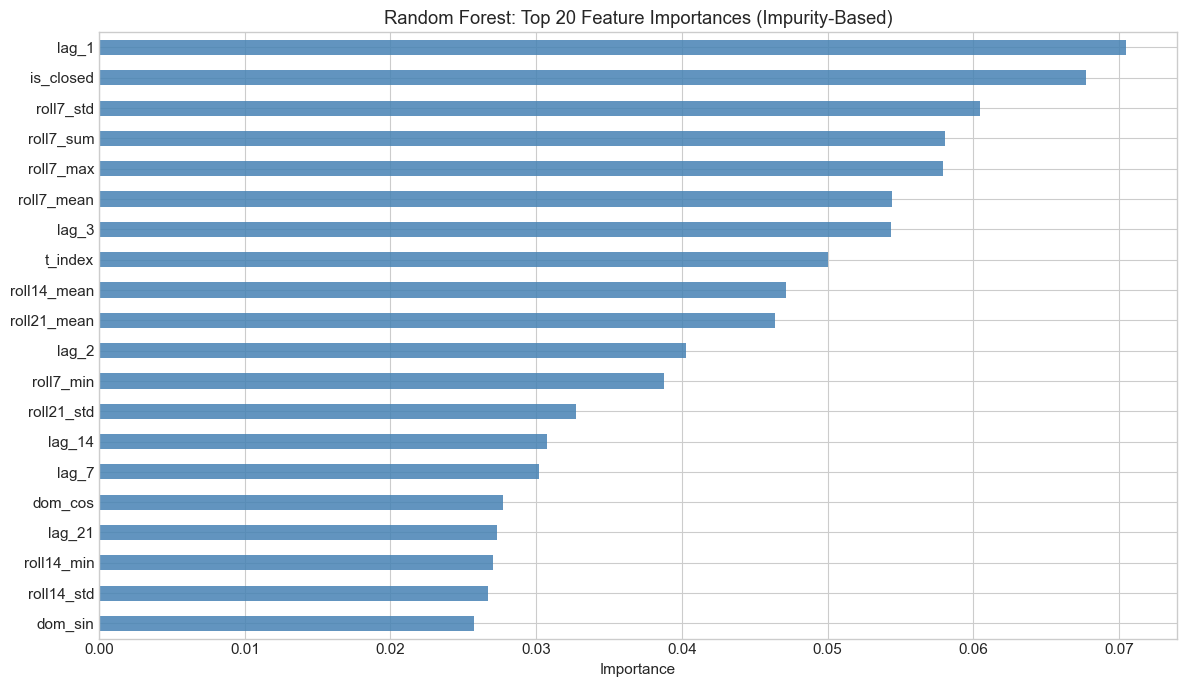


Top 15 Features:
  lag_1               : 0.0705
  is_closed           : 0.0677
  roll7_std           : 0.0605
  roll7_sum           : 0.0580
  roll7_max           : 0.0579
  roll7_mean          : 0.0544
  lag_3               : 0.0544
  t_index             : 0.0501
  roll14_mean         : 0.0472
  roll21_mean         : 0.0464
  lag_2               : 0.0403
  roll7_min           : 0.0388
  roll21_std          : 0.0328
  lag_14              : 0.0308
  lag_7               : 0.0302


In [12]:
importances = pd.Series(rf_model.feature_importances_, index=FEATURE_COLS).sort_values(ascending=False)
top_n = 20

fig, ax = plt.subplots(figsize=(12, 7))
importances.head(top_n).plot(kind='barh', ax=ax, color='steelblue', alpha=0.85)
ax.invert_yaxis()
ax.set_title(f'Random Forest: Top {top_n} Feature Importances (Impurity-Based)')
ax.set_xlabel('Importance')
plt.tight_layout()
plt.show()

print("\nTop 15 Features:")
for feat, imp in importances.head(15).items():
    print(f"  {feat:<20}: {imp:.4f}")

---
## 11. Residual Analysis

We perform residual diagnostics on the champion/best model to detect systematic bias and identify periods the model struggles.

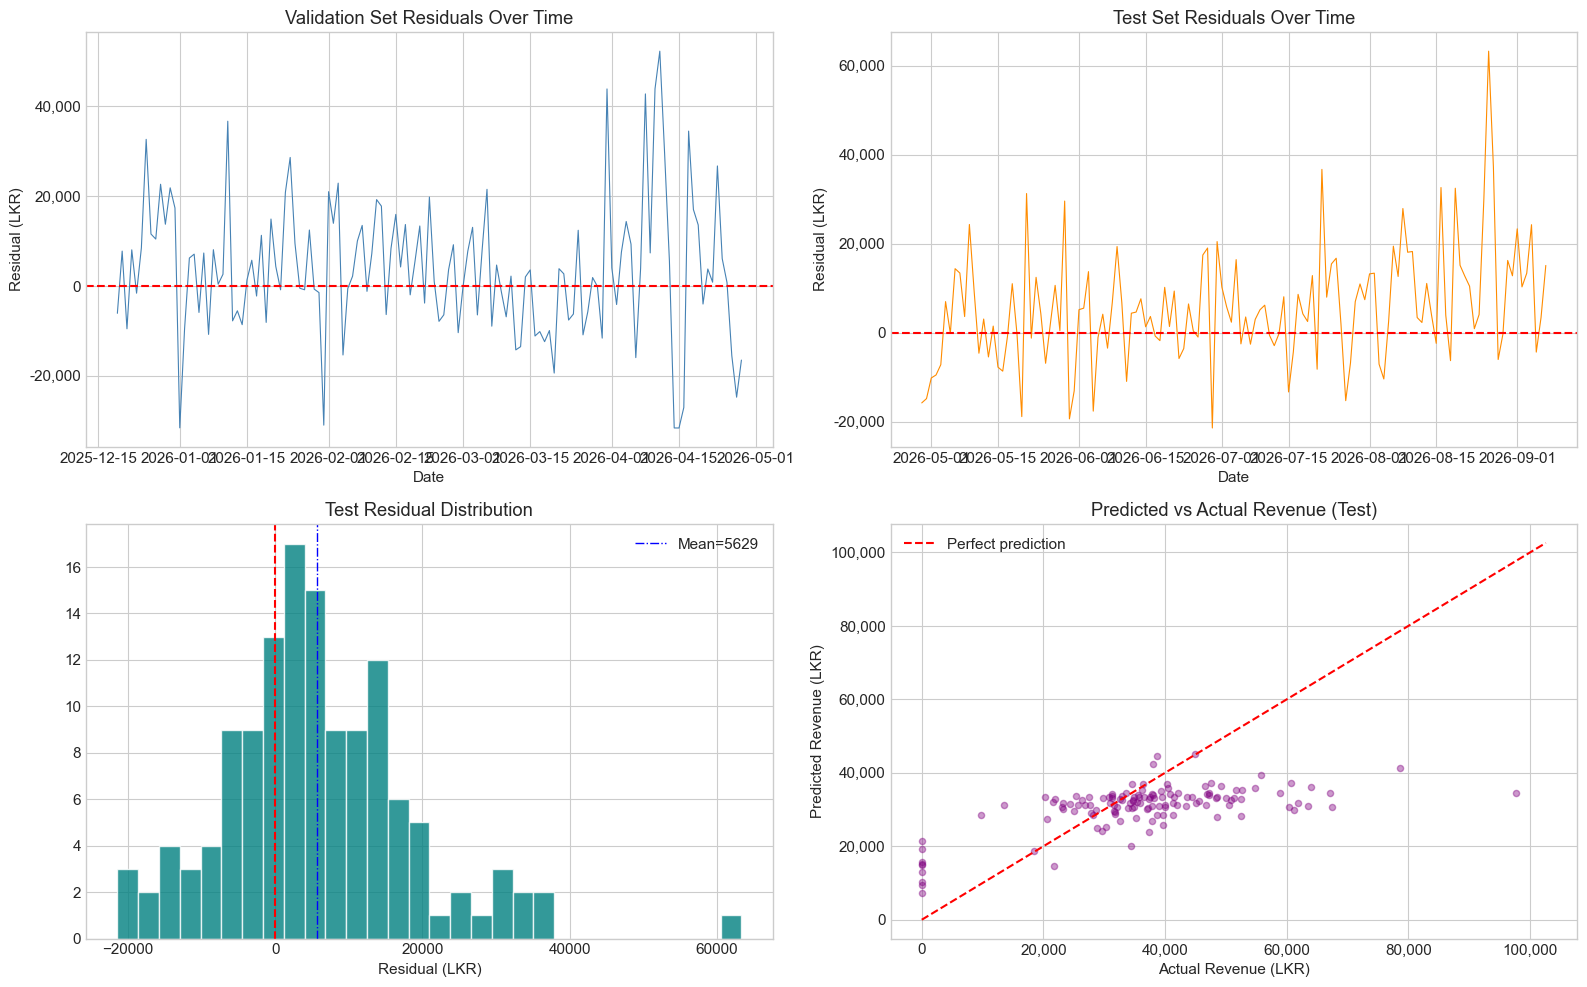


Test Residual Statistics:
  Mean   : +5,628.64 LKR  (bias — positive = under-predicting)
  Std    : 12,777.26 LKR
  Min    : -21,413.04 LKR
  Max    : +63,289.59 LKR

Shapiro-Wilk normality test (sample, n=50): p=0.3179
Note: Normally distributed residuals indicate well-calibrated predictions.


In [13]:
# Use Random Forest predictions for residual analysis (as example champion)
residuals_val = y_val.values - val_pred_rf
residuals_test = y_test.values - test_pred_rf

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Val residuals over time
axes[0, 0].plot(val_df['Date'], residuals_val, color='steelblue', linewidth=0.8)
axes[0, 0].axhline(0, color='red', linewidth=1.5, linestyle='--')
axes[0, 0].set_title('Validation Set Residuals Over Time')
axes[0, 0].set_xlabel('Date')
axes[0, 0].set_ylabel('Residual (LKR)')
axes[0, 0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Test residuals over time
axes[0, 1].plot(test_df['Date'], residuals_test, color='darkorange', linewidth=0.8)
axes[0, 1].axhline(0, color='red', linewidth=1.5, linestyle='--')
axes[0, 1].set_title('Test Set Residuals Over Time')
axes[0, 1].set_xlabel('Date')
axes[0, 1].set_ylabel('Residual (LKR)')
axes[0, 1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Residual distribution
axes[1, 0].hist(residuals_test, bins=30, color='teal', alpha=0.8, edgecolor='white')
axes[1, 0].axvline(0, color='red', linewidth=1.5, linestyle='--')
axes[1, 0].axvline(residuals_test.mean(), color='blue', linewidth=1, linestyle='-.',
                   label=f'Mean={residuals_test.mean():.0f}')
axes[1, 0].set_title('Test Residual Distribution')
axes[1, 0].set_xlabel('Residual (LKR)')
axes[1, 0].legend()

# Predicted vs Actual scatter
axes[1, 1].scatter(y_test, test_pred_rf, alpha=0.4, s=20, color='purple')
lim = max(y_test.max(), test_pred_rf.max()) * 1.05
axes[1, 1].plot([0, lim], [0, lim], 'r--', linewidth=1.5, label='Perfect prediction')
axes[1, 1].set_title('Predicted vs Actual Revenue (Test)')
axes[1, 1].set_xlabel('Actual Revenue (LKR)')
axes[1, 1].set_ylabel('Predicted Revenue (LKR)')
axes[1, 1].legend()
axes[1, 1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
axes[1, 1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))

plt.tight_layout()
plt.show()

print(f"\nTest Residual Statistics:")
print(f"  Mean   : {residuals_test.mean():+,.2f} LKR  (bias — positive = under-predicting)")
print(f"  Std    : {residuals_test.std():,.2f} LKR")
print(f"  Min    : {residuals_test.min():+,.2f} LKR")
print(f"  Max    : {residuals_test.max():+,.2f} LKR")

# Normality test
_, p_norm = stats.shapiro(residuals_test[:50])  # Shapiro-Wilk on sample
print(f"\nShapiro-Wilk normality test (sample, n=50): p={p_norm:.4f}")
print("Note: Normally distributed residuals indicate well-calibrated predictions.")

---
## 12. Model Development Decision Log

| Decision | Rationale |
|---|---|
| Temporal 70/15/15 split (no shuffle) | Prevents future leakage into training; standard for time-series ML |
| Champion selected on Validation WAPE, not Test WAPE | Test set must remain strictly unseen until final reporting |
| WAPE as primary KPI | MAPE undefined for zero-revenue days; WAPE is always well-defined |
| Clip predictions at 0 | Revenue cannot be negative |
| Ridge with StandardScaler | Ridge's regularisation depends on feature scale; scaling required |
| RF without scaling | Tree-based models are scale-invariant; scaling adds no benefit |
| LightGBM early stopping on val | Prevents overfitting; automatically finds optimal n_estimators |
| n_estimators=300 for RF | Sufficient convergence (OOB error plateaus); beyond 300 gives diminishing returns |

### AI-use Declaration (IT24102726)
This notebook was written by the student author. Generative AI tools were used to check sklearn/LightGBM/XGBoost API signatures only. All model design, hyperparameter choices, and interpretations are the author's own work based on course content and literature review.